# SQDMetal floating-transmon Palace example — tapered-inset transmon with a λ/2 readout (Quantcore PDK rebuild)

**What the chip is.** sqdlab SQDMetal's `doc-sphinx/source/examples/Palace_Eigenmode_FloatingTransmon.ipynb`
(<https://github.com/sqdlab/SQDMetal>, **Apache-2.0**; spec `docs/designs/sqdmetal/floating_transmon.md`): a
Quantum Metal design (SQDMetal `TransmonTaperedInsets` + Metal `CoupledLineTee`, `RouteMeander`, `RouteStraight`,
`OpenToGround`) for a Palace eigenmode run (3 modes from 3 GHz, silicon 500 µm); no stored outputs. One floating
tapered-pad transmon whose readout connector pad runs a **λ/2 meander** (6.8 GHz on Si, 8.96 mm) to a
`CoupledLineTee` with an **open** termination (220 µm coupled, 5 µm ground strip) on a short straight line between
two open ends (the simulation adds 50 Ω ports there). Target f_q 4.5 GHz.

This notebook **rebuilds** it with our components, routes, netlist and LOM on the Quantcore PDK (not a replica);
we distribute the rebuild under GPL-3.0.

| topic | SQDMetal source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | Metal chip 4 × 4 mm centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die with its frame, device ID "SQD-FT" (Designer = source + (2000, 2000) µm before centring) |
| line ends / pads | two `OpenToGround`s at x = −1.8 / 0 mm (Palace ports) | two small `BondPad`s (100 × 100 µm) as the line's 50 Ω ports, **on the die edges** (outer etch 100 µm, `frame.pad_edge`, from the west / east edge, PDK pad rule): the line is 6.9 mm instead of 1.8 mm |
| substrate | silicon, 500 µm | sapphire 650 µm, εr 10.25 |
| junction | a junction line, L_J not given (target 4.5 GHz) | the Quantcore trilayer junction **sized for the target 4.5 GHz**: 0.31 × 0.6 µm, L_J ≈ 10.9 nH — R_n ≈ 72 kΩ, ⚠ above the 40–50 kΩ window (a 45 kΩ junction would give ≈ 5.6 GHz) |
| cheese | none (`MakeGDS(design).export(..., export_type="positive")` — SQDMetal's exporter perforates the ground only through an explicit `perforate_layer`, which the example never calls) | the PDK band (chip `cheese` `"auto"`, at least 4 µm clear of 3/0) |
| components | `TransmonTaperedInsets`, `CoupledLineTee` + `RouteMeander` | Quantcore re-implementation of `TransmonTaperedInsets` (Apache-2.0) with the source options; the tee + meander as one qcc open hanger route |
| placement | — | centred in the die (the content sat ≈ 710 µm north of the centre; moved south. In x the pads on both edges span the die, so no x shift) |

**Kept:** the λ/2 length 8960 µm counted as in the source (connector wire 410 µm inside the cell + route 8550 µm),
the 220 µm / 5 µm coupled section at the source's position, meander spacing ≈ 100 µm (r = 40 µm, the source
fillet), the targets (f_q 4.5 GHz, f_r 6.8 GHz on Si) and the sim group.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the two bond pads that end the line, the line between them, the qubit, its λ/2 readout hanging on the line, and then the whole chip (the targets, the sim group, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `floating_transmon.v1.ipynb`; both save the same `floating_transmon.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/floating_transmon/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs") / "sqdmetal"        # design JSON + final snapshots
STEPS = Path("build/snapshots") / "floating_transmon"       # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 2000, 2000                              # Metal's 4 × 4 mm chip is centred on (0, 0)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and every FEM export, the frame and the pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction from the PDK rule.** The source's target f_q is 4.5 GHz. `size_junction(4.5, C_Σ)` solves the
trilayer junction on the PDK rule (Nb Δ 1.4 meV, R_n·A 13.5 kΩ·µm², C_J 50 fF/µm²) for the qubit's C_Σ (97.9 fF
without the junction, from this design's LOM before the rebuild: f_q 4.10 GHz with 14 nH, C_J 0). The result is a
0.31 × 0.6 µm junction, L_J ≈ 10.9 nH, C_J ≈ 9.3 fF — **R_n ≈ 72 kΩ, outside the 40–50 kΩ window**; the sizing line
prints the note. Kept: the target is the source's (values outside the PDK margins are flagged, not retuned).
`trilayer_junction` turns L_J into the cell's `junction_type` + `junction_params`.

In [5]:
from quantcore_circuits.circuit.bridges import size_junction
SIZED = size_junction(4.5, 97.9, c_includes_junction=False)
JJ_PARAMS, JUNCTION = trilayer_junction("TransmonTaperedInsets", lj_nH=SIZED.lj_nH)
print(JUNCTION, f"R_n {SIZED.rn_kohm:.0f} kΩ, fingers {SIZED.finger_width} × {SIZED.second_finger_width} µm;", *SIZED.notes)

{'Lj_nH': 10.862, 'Cj_fF': 9.3} R_n 72 kΩ, fingers 0.31 × 0.6 µm; R_n 72.0 kΩ is outside the process window 40–50 kΩ (f_q 4.5 GHz with C_Σ 107.3 fF needs E_J/h 15.2 GHz)


# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die, the bond pads, the readout line, the qubit,
its readout resonator, and then the whole chip. Each segment is one cell with one picture of the chip so far (live,
KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the line is
drawn before the qubit and the readout after it (it starts at the qubit's readout pad and hangs on the line).
Coordinates are the source's + (`X0`, `Y0`) until the centring in Design 8.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm Quantcore die with its frame (device ID SQD-FT) |
| 2 | the two bond pads that terminate the line (the source's Palace ports), on the west / east die edges |
| 3 | the readout line `FL` between them |
| 4 | the qubit: a floating `TransmonTaperedInsets` with its trilayer junction |
| 5 | the λ/2 readout `R1`, from the qubit's readout pad to an open hanger on the line |
| 6 | the coupling: none (one qubit) |
| 7 | the control routing: none (the source has no charge or flux line) |
| 8 | the whole chip: the targets, the sim group, the centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens the die: the 7.5 × 7.5 mm Quantcore die placed so the source's 4 × 4 mm area sits
in its middle (every source position + (2000, 2000) µm). The PDK frame: L dicing markers (1000/0), 3 × 3 alignment
grids (1001/0), the chip boundary (100/0), the device ID on a free edge. The chip `cheese` stays `"auto"`: the
source has no cheese, so the PDK band is drawn.

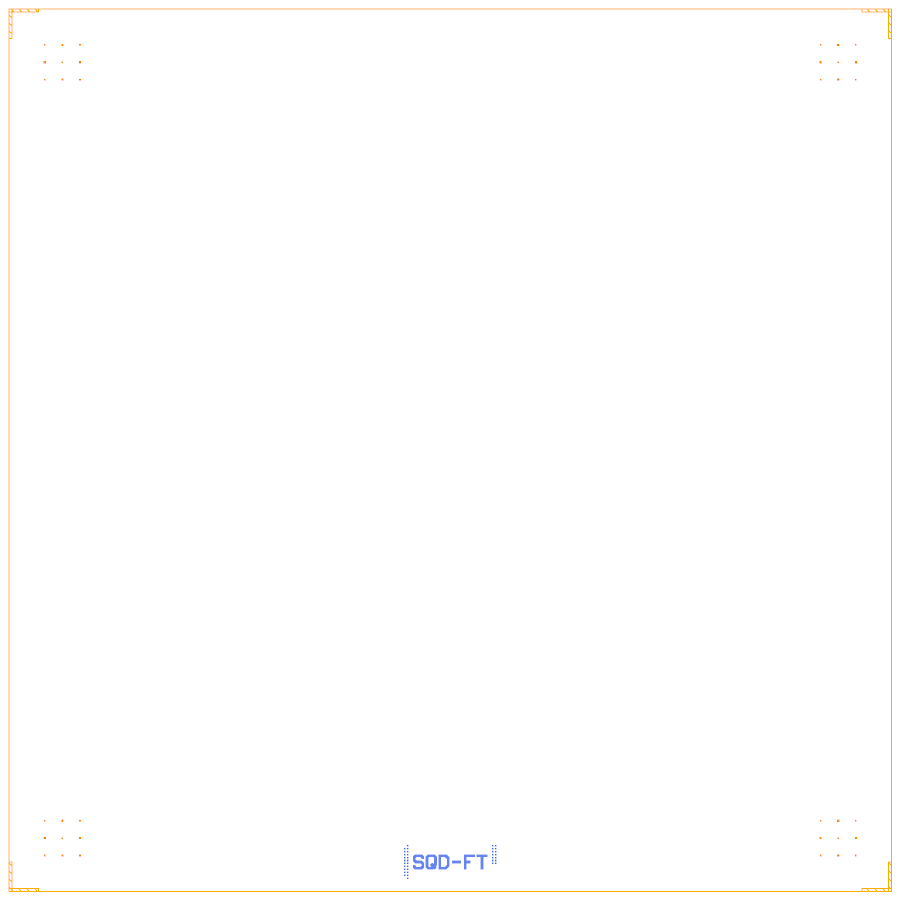

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/floating_transmon/s1_die.png')

In [6]:
d = Designer("floating_transmon", box=(-1750, -1750, 5750, 5750), chip={"name_chip": "SQD-FT"}, live=LIVE)
layout_step(d, STEPS / "s1_die.png", size=(900, 900), width=360)

## Design 2 · Bond pads: the two line ends and the pad rule

The source's line ends are open (`OpenToGround`), and Palace adds 50 Ω ports there; our LOM needs real ports, so
two small `BondPad`s (100 × 100 µm pad, 50 µm taper, 30 µm gap) terminate the line. **PDK rule:** a pad's outer
etch edge sits `frame.pad_edge` (100 µm) from the die edge, so the pads go on the line's y with
`edge="w"` / `edge="e"`: each slides perpendicular to its edge until its etch is 100 µm from it.

The first picture is the chip so far, the second zooms on the west pad.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_L | `BondPad` | w | 100.0 | ✓ |
| P_R | `BondPad` | e | 100.0 | ✓ |

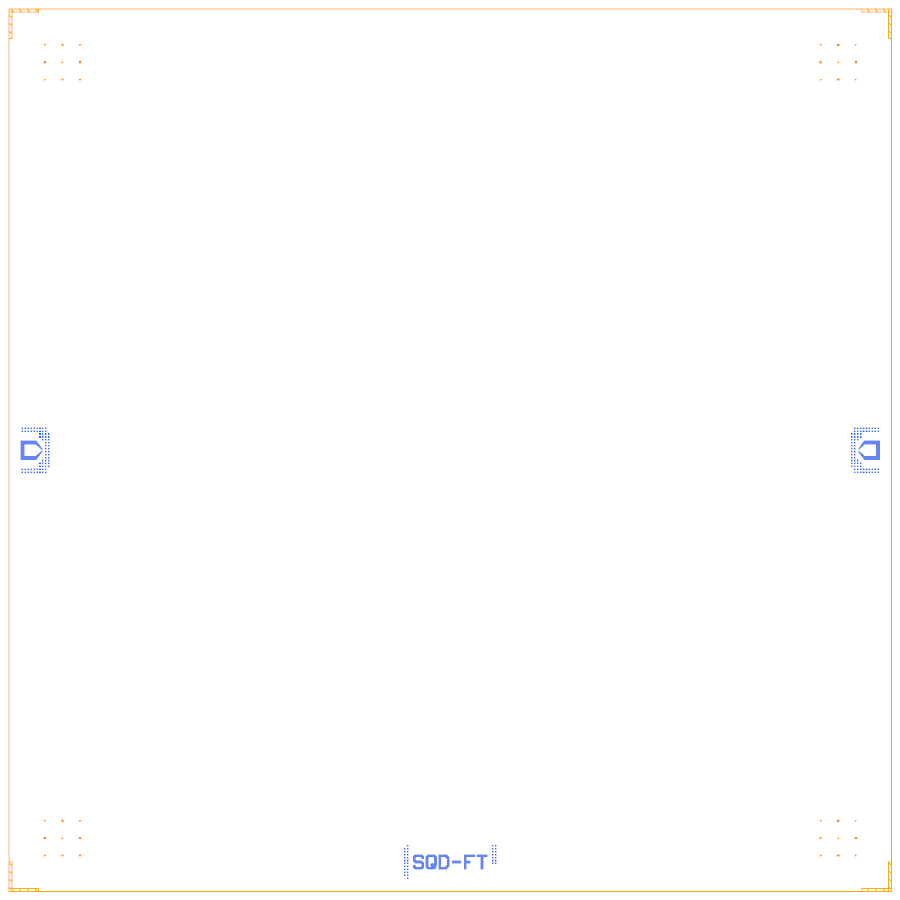

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `P_L`, `P_R`.

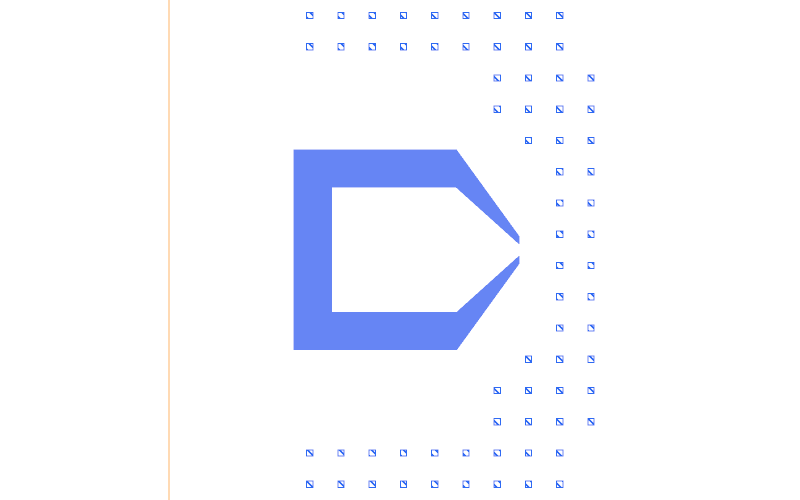

In [7]:
PAD = dict(pad_width=100, pad_height=100, taper_length=50, pad_gap=30)
with d.batch():
    pl = d.add("P_L", "BondPad", at=(X0 - 1800, Y0), rot=270, edge="w", **PAD)   # the source's otg_left end
    pr = d.add("P_R", "BondPad", at=(X0, Y0), rot=90, edge="e", **PAD)            # otg_right
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "s2_pads.png", size=(900, 900), width=360)
x, y = port_xy(d, "P_L.a")
snap(d, STEPS / "2_pad.png", box=(-1760, y - 200, x + 100, y + 200), size=(800, 500), width=360);

## Design 3 · Readout: the line between the pads

**The line** `FL` between the two pads (10/6 µm, straight). With the pads on the die edges it runs 6.9 mm instead of
the source's 1.8 mm; it is a 50 Ω through-line, so its length sets no frequency. The readout hangs on it (Design 5).

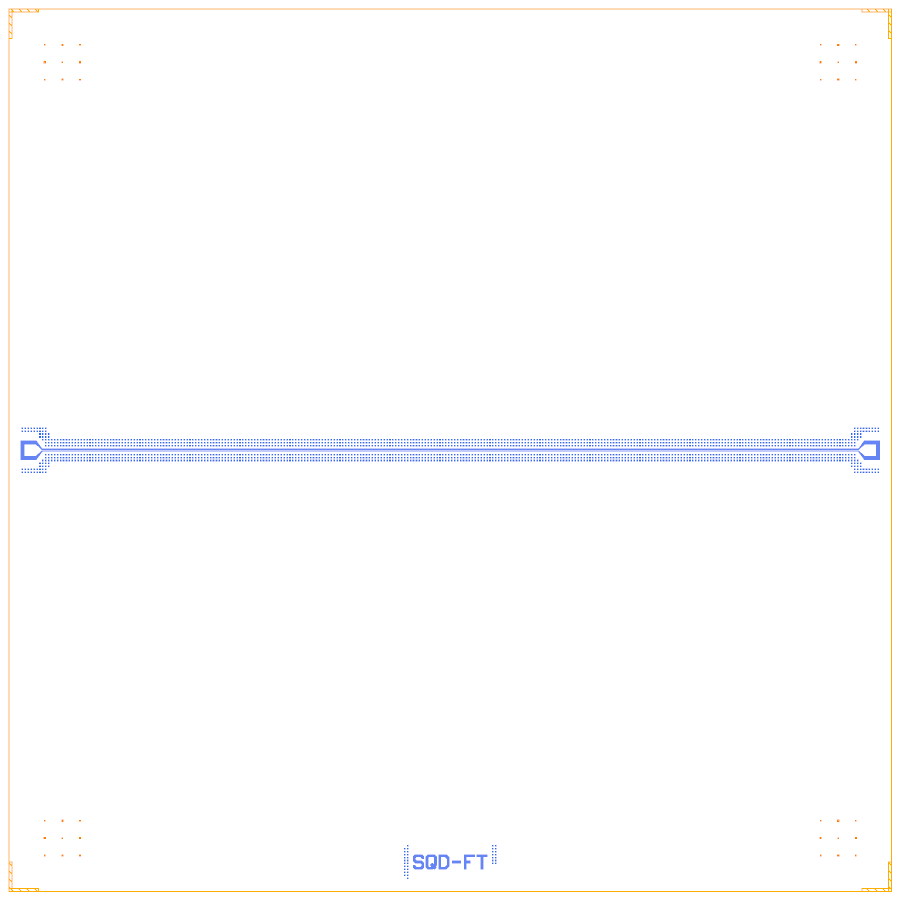

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('build/snapshots/floating_transmon/s3_line.png')

In [8]:
with d.batch():
    fl = d.route("FL", pl.a, pr.a)
layout_step(d, STEPS / "s3_line.png", size=(900, 900), width=360)

## Design 4 · Qubit placement: the tapered-inset transmon

**The qubit:** `TransmonTaperedInsets`, Quantcore's re-implementation of SQDMetal's cell (Apache-2.0), with the
source options: two 800 × 110 µm pads 100 µm apart, `taper_height` 0, a 100 µm junction line, the 1000 × 800 µm
pocket, orientation 90°, and the `readout` connection pad (200 × 30 µm, 100 µm beyond the pad) whose wire ends at
SQDMetal's pin, 700 µm from the centre. The trilayer junction of the junction cell above is drawn across the pad gap
(`junction_params`). Ports: `readout`, the SQDMetal placement pins (`top_*_pin`, `bottom_*_pin`, `*_pocket_pin`,
marks for charge lines or capacitors) and the junction attachment points `squid_a` / `squid_b`.

The first picture is the chip so far, the second zooms on the qubit.

<TransmonTaperedInsets Q1 ports=['bottom_left_pin', 'bottom_pocket_pin', 'bottom_right_pin', 'readout', 'squid_a', 'squid_b', 'top_left_pin', 'top_pocket_pin', 'top_right_pin']>


Q1.readout (x, y, direction): (1800.0, 3000.0, 180.0)


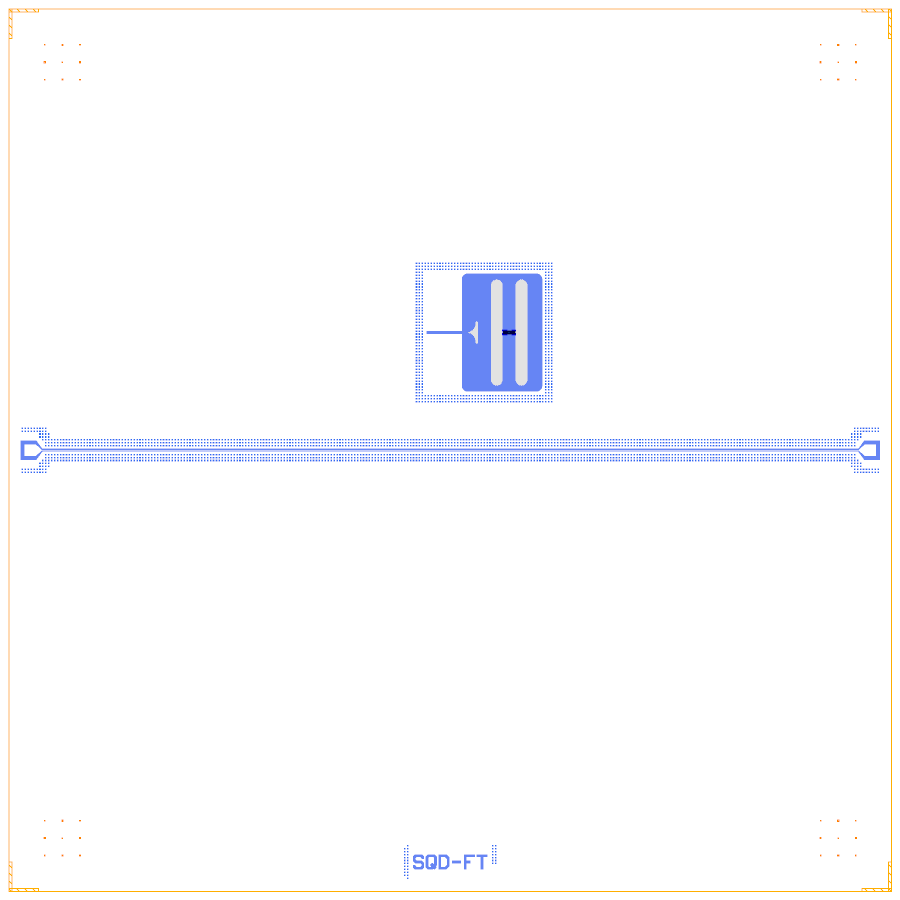

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `Q1`.

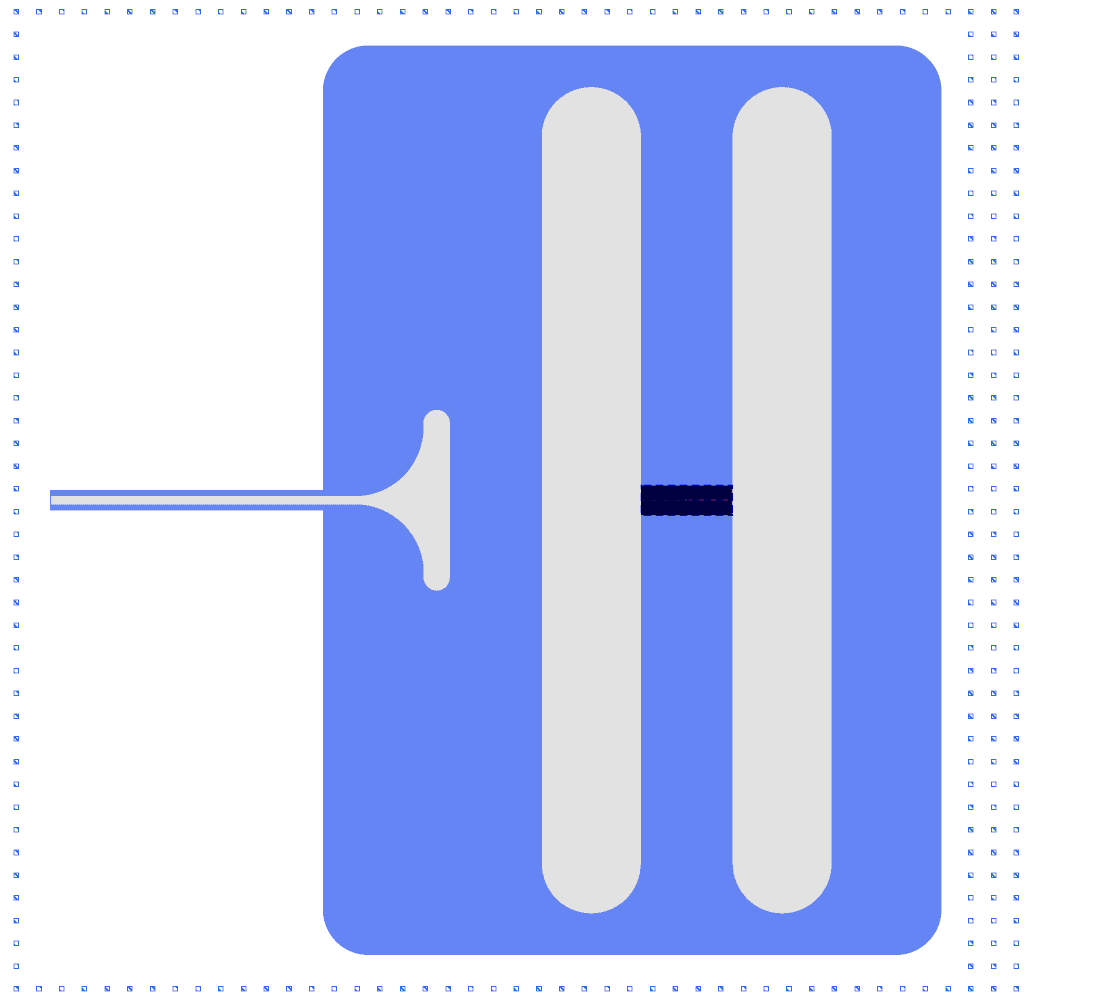

In [9]:
TTI = dict(connection_pads={"readout": {"pad_gap": 100}}, inductor_height=100, pad_gap=100, taper_height=0)  # source options
WIRE = 410.0                                     # SQDMetal readout_wire (connection pad top at 290 µm → pin at 700 µm)
q1 = d.add("Q1", "TransmonTaperedInsets", at=(X0 + 500, Y0 + 1000), rot=90, junction=JUNCTION, **JJ_PARAMS, **TTI)
print(q1)
print("Q1.readout (x, y, direction):", port_info(d, "Q1.readout"))
layout_step(d, STEPS / "s4_qubit.png", size=(900, 900), width=360)
snap(d, STEPS / "3_qubit.png", box=(X0 - 250, Y0 + 450, X0 + 950, Y0 + 1550), size=(1100, 1000), width=400);

## Design 5 · Readout: the λ/2 readout on the line

**The readout** (λ/2, 8960 µm including the 410 µm connector wire inside the cell): readout pin → meander (KQC's,
9 turns, r = 40 µm) → the 220 µm coupled section with a 5 µm ground strip → an **open** end at its west end
(`end="open"`, `direction="backward"`). `FL.hanger(near=(x, y), ...)` centres the coupled section at the line point
nearest (1000, y_FL) — the source's `CoupledLineTee` position, independent of where the line starts (it now starts
≈ 1.7 mm further west, at the west pad).

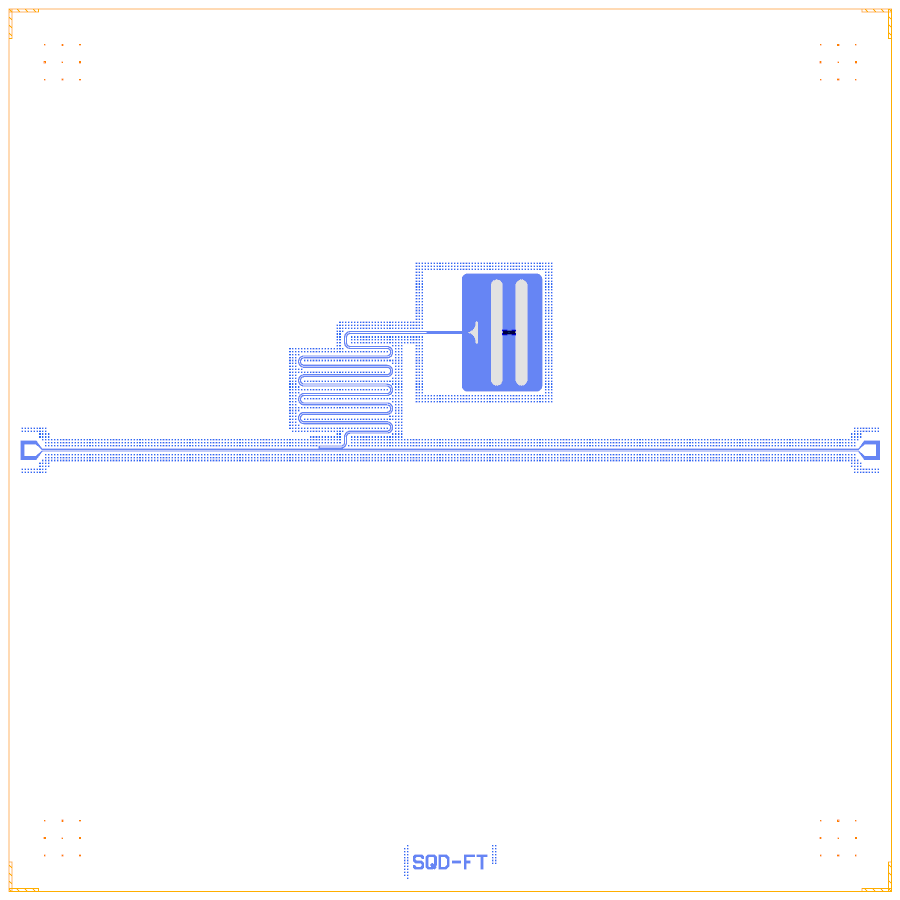

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** 1 route(s) `R1`.

{'FL': 6940.0, 'R1': 8550.0}


In [10]:
with d.batch():
    d.route("R1", q1.readout, fl.hanger(near=(X0 - 1000, Y0), length=220, side="left", ground_gap=5,
                                        direction="backward", end="open"), meander=8960 - WIRE, r=40).set(meanders=9)
layout_step(d, STEPS / "s5_readout.png", size=(900, 900), width=420)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

## Design 6 · Coupling: none (one qubit)

## Design 7 · Routing: no control lines

The source drives the qubit through its readout; the cell's placement pins (`top_*_pin`, `bottom_*_pin`,
`*_pocket_pin`) mark where charge lines or capacitors could attach, and none is used.

## Design 8 · The whole chip: targets, sim group, centring, save

**Targets, sim group, centring, save.** The source's targets (f_q 4.5 GHz, f_r 6.8 GHz on silicon) go into the
design; one sim group holds the qubit, its readout and the line (a Q3D C-matrix and an eigenmode / EPR job, the
source's own run being a Palace eigenmode). `center_in_die` applies the PDK placement rule: with the pads on the
edges the content spans the die in x, but it sat ≈ 710 µm north of the centre (the qubit above the line), so
everything moves south (instance positions, the hanger's `near` point; the pads stay on their edges). Then the
design is saved with `save_design`, which compares it with the file it replaces (the previous run's): it should say
*same design*, and the file keeps the previous key order.

centring shift (µm): (0.0, -710.0)


**Same design as before:** `examples/designs/sqdmetal/floating_transmon.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer floating_transmon: 3 instances, 2 routes, live=False> → examples\designs\sqdmetal\floating_transmon.json | R1 8550.0 µm


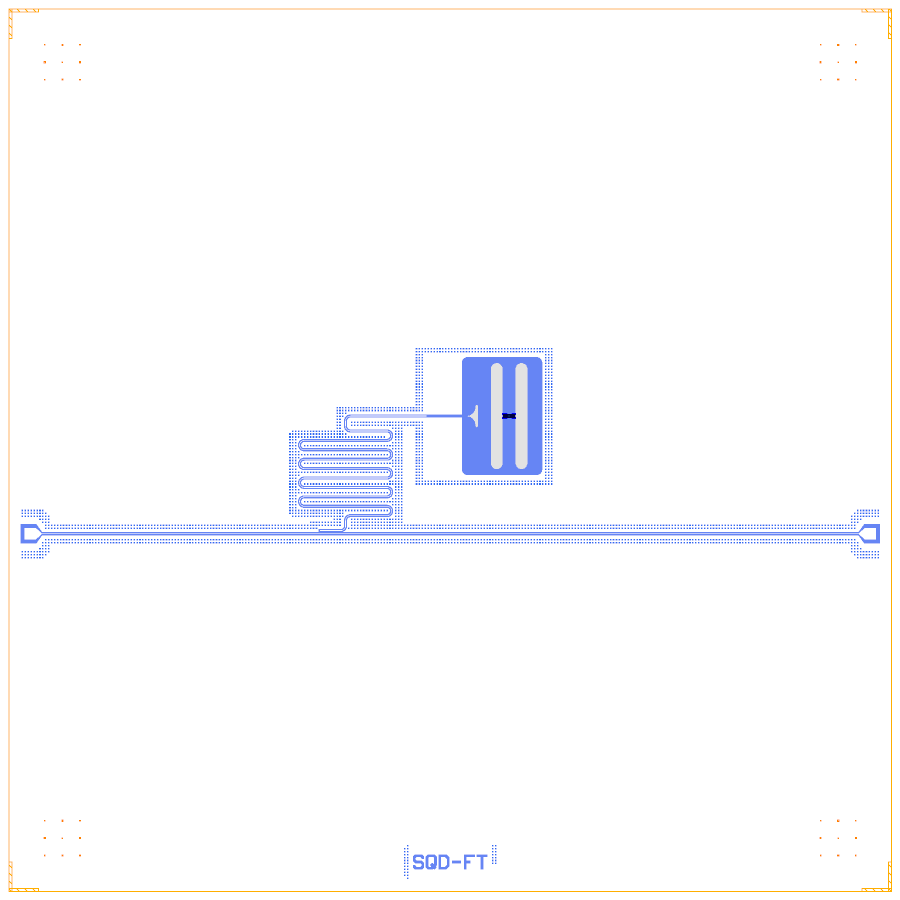

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/floating_transmon/s8_chip.png')

In [11]:
d.targets(Q1={"f_q_GHz": 4.5}, R1={"f_GHz": 6.8})
d.sim_group("Q1R1", ["Q1", "R1", "FL"])
DX, DY = center_in_die(d)
print("centring shift (µm):", (DX, DY))
rebuild(d)
DESIGN, same = save_design(d, OUT / "floating_transmon.json")
display(Markdown(same))
print(d, "→", DESIGN, "| R1", round(d.result.route_lengths()["R1"], 1), "µm")
layout_step(d, STEPS / "s8_chip.png", size=(900, 900), width=420)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab; there must be none. **Warnings** are connectivity or geometry notes
to read (often by design). **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside
the PDK margins: flagged, never enforced — the rebuild keeps the source's choices. `pdk_report(d)` sums up the PDK
side: the cheese source, the content centre against the die centre, the junction types and the design warnings.
Expected here (from the v1 run): **no errors**; `dangling_port` warnings for the `TransmonTaperedInsets` placement pins
(`top_*_pin`, `bottom_*_pin`, `*_pocket_pin`: SQDMetal's marks for charge lines or capacitors, not CPW ends; the
source uses none here) and the junction attachment points `squid_a` / `squid_b`. One PDK design warning: `pdk_rn`
on Q1 (R_n ≈ 72 kΩ, sized for the source's 4.5 GHz target; flagged, not retuned).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` maps the ports onto circuit nodes. `TransmonTaperedInsets` is a floating transmon: two pad nodes with
C to ground and between them, the junction across them, and the readout connection pad with its 410 µm wire as one
node (C to ground and to the near pad), so the wire loads the λ/2 as a lumped C. The readout is a λ/2 `TLres`
(claw at one end, open at the other); its open coupled section is a `HANGER` κ element to the line node, and the
two pads are the line's 50 Ω ports. The netlist lists the six placement pins as unconnected (nothing attaches
there).

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Q1 / R1 ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("Q1.readout", "Q1.squid", "R1")))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat normal modes of the whole circuit (frequencies, κ into the two 50 Ω pads, anharmonicities), then the
QuTiP-dressed values next to the source's targets (f_q 4.5 GHz, λ/2 6.8 GHz — on silicon; this rebuild is on
sapphire, so the readout lands a little higher). Expected: f_q ≈ 4.5 GHz (the junction was sized for it),
α ≈ −180 MHz, f_r ≈ 6.9 GHz (the v1 run: f_q 4.486 GHz, α −200.8 MHz, f_r 6.907 GHz, χ −0.41 MHz) with a small κ from the 220 µm open coupled section.

In [ ]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res, {"Q1": {"f_q_GHz": 4.5}, "R1": {"f_GHz": 6.8}})))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) the normal modes (QuCat; the circle is the qubit, the square the readout; filled
markers are the QuTiP dressed values; red bars are the design's targets), (b) the readout's dispersive shift |χ|.

In [ ]:
plot_lom({"chip": res}, STEPS / "lom.png", targets={"Q1": {"f_q_GHz": 4.5}, "R1": {"f_GHz": 6.8}},
         title="floating_transmon: LOM")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. Shorten the readout by 500 µm (route 8550 → 8050 µm, λ/2 8960 → 8460 µm): f_r rises by ≈ 6 % (≈ +0.4 GHz), the
qubit–readout detuning grows and |χ| drops. Done on a copy (`design_copy`), so `floating_transmon.json` keeps the
source's 8960 µm.

In [ ]:
d2 = design_copy(DESIGN)
d2["R1"].set(meander=8960 - WIRE - 500)
after = simulate_lom(d2.lom(), d2.design)
display(Markdown("**R1: 8550 → 8050 µm**\n\n" + params_delta_md(res, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/sqdmetal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (its margin), puts ports where lines leave the box, makes each junction a lumped port and writes one
job folder per group and analysis under `build/jobs/` (the group's own analyses: a Q3D C-matrix and an eigenmode /
EPR job). Simulation exports never have cheese; airbridges are dropped unless asked for. The table lists each job's
ports and C-matrix nets (named after the islands, pads and routes, so the results map back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is
`qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/sqdmetal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix of the sim group
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says what the export
left out (this chip has no airbridges).

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the group `Q1R1`: the qubit's two pads, its readout pad with the connector wire, the readout and
the line as named nets. Each net is named after its LOM node, so the matrix goes straight into the circuit
(Results 3). `fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same box in HFSS eigenmode (the source's own analysis was a Palace eigenmode): the junction is a lumped
L_J ‖ C_J sheet, the line ends in the pads' 50 Ω ports, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT,
never KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α and
χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the line between the two pads, where the readout's open coupled section shows up
as a notch. The library cannot hand the solved eigenmode **mesh** itself to a driven setup (no such option yet), so
`driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the eigenmode job's mesh seeds,
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it.

In [ ]:
f_r1 = res.params.get("R1.f_GHz")                        # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1R1", jobs_eig["Q1R1"][0], keep_eig["Q1R1"], f_guess=f_r1)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1R1"]:
    display(Markdown(driven_md(keep_drv["Q1R1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies as dashed
lines. The table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q1": res.params.get("Q1.f_q_GHz"), "R1": f_r1}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: the qubit's mode is the one its junction participates in most, the readout's the
remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms, κ = f/Q of
the 50 Ω-terminated box. The driven run adds the readout's S21 notch.

In [ ]:
fem_values = {}
if keep_eig["Q1R1"]:
    fem_values = epr_values(keep_eig["Q1R1"], {"Q1": "R1"}, {"R1": f_r1})
if keep_drv["Q1R1"]:
    fem_values.update({f"driven {k}": v for k, v in driven_values(keep_drv["Q1R1"], "R1", f_r1).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for k, v in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ from pyEPR and the "
          "readout's S21 notch.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates by the C-matrix values (matched by net name)
and the same LOM runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM
on the component estimates (LOM 1), next to the targets of the design (f_q 4.5 GHz, f_r 6.8 GHz).

In [ ]:
from quantcore_circuits.circuit.fill import fill

keys = ["Q1.f_q_GHz", "Q1.alpha_MHz", "R1.f_GHz", "R1.chi_MHz", "R1.kappa_MHz"]
rows = []
if keep_q3d["Q1R1"]:
    on_fem = simulate(fill(lb.model, DESIGN, keep_q3d["Q1R1"]), max_modes=2).params
    rows += [(k, res.params.get(k), on_fem.get(k), "LOM on the Q3D C-matrix") for k in keys]
rows += [(k, res.params.get(k), fem_values[k], "eigenmode + pyEPR") for k in keys if k in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the design's targets

The design has its own targets (the source's): **f_q 4.5 GHz** and **f_r 6.8 GHz**. From the v1 run the LOM puts the
qubit within its tolerance (4.486 GHz, f_q ± 20 MHz) and the readout 107 MHz high (6.907 GHz, f_r ± 10 MHz): the
source's 6.8 GHz is on silicon, so on sapphire the same length lands higher, and the feedback lengthens the readout
(the meander takes it).

`target_copy(DESIGN, {})` writes the design with its own targets to `build/floating_transmon_target.json`.
`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on the qubit–readout pair — on the Q3D
values when a solve was kept — and picks one value per quantity (the consensus). `loop.feedback` anchors a surrogate
on that point and proposes the knobs that put the targets inside their tolerances; the proposal is written as
revision 1, built and netlist-checked. **No PDK L_J bounds here:** the junction was sized for the source's 4.5 GHz at
R_n ≈ 72 kΩ, outside the 40–50 kΩ window (`pdk_rn`, flagged, not retuned); `pdk_lj_bounds` would first clip L_J into
the window (≈ 5.4 GHz) and report the qubit target out of reach. The feedback's own bounds (0.4–2 × each knob) apply.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (f_q 4.5, f_r 6.8 GHz)
BOUNDS = None                                    # not pdk_lj_bounds(DESIGN): the junction is outside the window
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/floating_transmon/revisions/`). Without
`RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's Q3D job is exported and solved
first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each
iteration's values against the targets and the knobs it moved; the plot the residual in tolerances (on target below
1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q1R1",)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `floating_transmon.json` (saved in Design 8) is the whole design:
`qcc build examples/designs/sqdmetal/floating_transmon.json` rebuilds `build/floating_transmon.oas` + its sidecar,
and the KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers 2/0 + 4/0 and spacer 50–53/0, and the frame (100/0, 1000/0, 1001/0).
**Cheese:** the source has none (its `MakeGDS` export perforates the ground only through `perforate_layer`, never
called), so the PDK band stands — drawn in the build (`cheese_source` `build`), at least 4 µm clear of 3/0. Corner rounding is fab-only
(`FULL_FAB`); `qcc mask examples/designs/sqdmetal/floating_transmon.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip (the pads on the west / east edges); the qubit with its readout connection pad and wire; the
trilayer junction across the 100 µm pad gap; the open coupled section on the line; the die frame's south-west
corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); and the qubit in the **fab view** (the mask from
Fab 1: 1/0 with the PDK cheese band, the 3/0 keep-out, the junction layers). In the layout snapshots the chip boundary
100/0 is drawn as an outline and the cheese band (KQC's ground-grid layer) is visible; the fab view shows the
mask itself.

In [ ]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
cx, cy = d.data["routes"]["R1"]["to"]["near"]               # centre of the coupled section (after centring)
show_snapshot(d, OUT / "floating_transmon.png", size=(1600, 1600))
show_snapshot(d, OUT / "floating_transmon_q1.png", box=(qx - 750, qy - 550, qx + 450, qy + 550), size=(1200, 1100), width=440)
show_snapshot(d, OUT / "floating_transmon_jj.png", box=(qx - 65, qy - 35, qx + 65, qy + 35), size=(1300, 700), width=360)
show_snapshot(d, OUT / "floating_transmon_coupler.png", box=(cx - 150, cy - 60, cx + 200, cy + 140), size=(1400, 800), width=480)
show_snapshot(d, OUT / "floating_transmon_frame.png", box=(-1750, -1750, -850, -850), size=(900, 900), width=300)
snap_file(Path("build") / "floating_transmon_fab.oas", OUT / "floating_transmon_fab_q1.png",
          box=(qx - 600, qy - 600, qx + 600, qy + 600), size=(1200, 1200), width=420);

## Summary

| | |
|---|---|
| **matches the source** | `TransmonTaperedInsets` with the source options and orientation; the 8960 µm λ/2 readout counted as in the source; the 220 µm / 5 µm open coupled section at the source's x; the targets; the eigenmode sim group |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; the line's ends are bond pads on the die edges (outer etch 100 µm), so the line is 6.9 mm long; content centred (≈ 710 µm south); sapphire; the Quantcore trilayer junction sized for 4.5 GHz (R_n ≈ 72 kΩ); the PDK cheese band in the mask |
| **substituted** | `CoupledLineTee` + `RouteMeander` as one open hanger route (KQC meander); bond pads instead of the Palace ports on `OpenToGround`s |
| **PDK design warnings** | `pdk_rn` on Q1 (≈ 72 kΩ, sized for the source's target) |
| layout | built in eight segments (die, the two line-end pads, the line, the qubit, the readout; no coupling and no control lines; the whole chip); the saved JSON is the v1 notebook's |
| feedback | the design's targets on a copy (f_q 4.5, f_r 6.8 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); no PDK L_J bounds (the junction is outside the window) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |